# Student Academic Performance Prediction Using Machine Learning
**Author:** Aryaman Tomar  
**Project Domain:** Educational Data Mining & Supervised Machine Learning  
**Dataset:** UCI Machine Learning Repository — Student Performance Dataset (Mathematics)  
**Primary Target Variable:** Final Grade (`G3`, Continuous Scale: 0–20)  
**Environment Compatibility:** Google Colab & Local Jupyter Notebook


---
## Section 1: Introduction

### 1.1 Project Overview & Problem Statement
Academic performance serves as a vital indicator of student success, institutional efficacy, and future socioeconomic opportunities. However, students frequently encounter academic difficulties that go unnoticed until term-end examinations, when corrective interventions are often too late. 

Educational institutions increasingly leverage predictive analytics to identify at-risk students proactively. By building accurate Machine Learning systems that forecast academic outcomes from demographic, socio-economic, behavioral, and historical school records, educators and administrators can allocate tutoring, counseling, and financial support before final examinations occur.

### 1.2 Project Objectives
1. **Data Ingestion & Hygiene:** Ingest and structure the benchmark UCI Student Performance Mathematics dataset (`student-mat.csv`) with zero manual setup in both local and cloud environments.
2. **Exploratory Data Analysis (EDA):** Identify distributions, patterns, anomalies, and correlations across demographic attributes, lifestyle habits, and historical grades.
3. **Robust Preprocessing:** Build an automated Scikit-Learn transformation pipeline implementing One-Hot Encoding for categorical features and Standard Scaling for numerical features while strictly preventing data leakage.
4. **Model Development & Benchmarking:** Train and rigorously compare three distinct supervised regression algorithms:
   - **Linear Regression** (Parametric baseline)
   - **Decision Tree Regressor** (Non-linear decision boundary model)
   - **Random Forest Regressor** (Ensemble bagging algorithm)
5. **Evaluation & Error Diagnostics:** Quantify predictive performance using standard regression metrics (**MAE**, **MSE**, **RMSE**, **R²**), diagnose residual errors, and examine actual vs. predicted grade alignments.
6. **Inference System:** Deliver a robust interactive prediction utility that accepts arbitrary student profiles, guarantees predictions conform to the official 0–20 grading scale, and maps scores to actionable performance tiers.

### 1.3 Machine Learning Approach
This problem is formulated as a **supervised regression task**, where the objective is to learn a mapping function $f: \mathcal{X} \rightarrow \mathcal{Y}$ such that $\hat{y} = f(\mathbf{x}) \in [0, 20]$, where $\mathbf{x}$ comprises $32$ student attributes and $\mathcal{Y}$ represents the final Mathematics grade `G3`.

```
Raw Data (395 records) 
   ├── Exploratory Data Analysis & Statistics
   ├── Train-Test Split (80:20 Partitioning, random_state=42)
   ├── Preprocessing Pipeline (Fitted solely on Training Set)
   │     ├── Numerical Features (15) ──> StandardScaler
   │     └── Categorical Features (17) ──> One-Hot Encoder
   ├── Model Training (Linear Regression, Decision Tree, Random Forest)
   ├── Model Evaluation (MAE, MSE, RMSE, R²)
   └── Champion Model Diagnostics & Interactive Inference Engine
```

### 1.4 Dataset Description
The dataset was collected by Paulo Cortez and Alice Silva (University of Minho, Portugal) from two secondary public schools (`Gabriel Pereira` and `Mousinho da Silveira`). It captures $33$ attributes categorized into:
- **Demographic & School Factors:** School, sex, age, address type, family size, parental cohabitation status.
- **Parental Background:** Mother and father education levels (`Medu`, `Fedu`) and occupations (`Mjob`, `Fjob`).
- **Educational Support & Motivation:** School support, family support, paid tutoring, extracurriculars, nursery attendance, ambition for higher education, home internet.
- **Social & Behavioral Factors:** Romantic relationships, family relationship quality, free time, social outings, alcohol consumption (workday & weekend), health, absences.
- **Academic Milestones:** First period grade (`G1`, 0–20), Second period grade (`G2`, 0–20), and Final grade (`G3`, 0–20).


---
## Section 2: Import Libraries

We import standard data science and machine learning libraries:
- `pandas` and `numpy` for data manipulation and numerical calculations.
- `matplotlib.pyplot` and `seaborn` for data visualization.
- `scikit-learn` modules for dataset partitioning, feature transformation, regression models, and performance metrics.


In [1]:
# Core data manipulation and numerical computation
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Preprocessing & Model Selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Scikit-learn: Regression Algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Scikit-learn: Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# System & Network utilities for reliable Colab/Jupyter execution
import os
import urllib.request
import zipfile
import io
import warnings

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic visualization styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Set reproducibility seed
RANDOM_STATE = 42

print("✓ All libraries imported successfully with consistent styling and random seed configured.")


✓ All libraries imported successfully with consistent styling and random seed configured.


---
## Section 3: Dataset Loading

To ensure seamless execution across both local Jupyter Notebooks and cloud platforms like Google Colab without requiring manual file uploads, we implement an automated loading routine. If `student-mat.csv` is not present in the active directory, the script automatically fetches the official UCI Machine Learning archive and extracts the Mathematics dataset.


In [2]:
DATA_FILE = "student-mat.csv"

# Check if dataset is available locally; if not, download automatically
if not os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' not found locally. Initiating automated download from UCI Machine Learning Repository...")
    uci_zip_url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    try:
        req = urllib.request.Request(uci_zip_url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=20) as response:
            outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))
            inner_zip_bytes = outer_zip.read('student.zip')
            inner_zip = zipfile.ZipFile(io.BytesIO(inner_zip_bytes))
            with open(DATA_FILE, 'wb') as f:
                f.write(inner_zip.read('student-mat.csv'))
        print("✓ Successfully retrieved and extracted student-mat.csv from UCI archive.")
    except Exception as exc:
        print(f"! Primary download encountered an issue ({exc}). Attempting reliable GitHub mirror...")
        mirror_url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv"
        urllib.request.urlretrieve(mirror_url, DATA_FILE)
        print("✓ Successfully fetched student-mat.csv from fallback mirror.")
else:
    print(f"✓ Found existing '{DATA_FILE}' in local working directory.")

# Note: The UCI Student Performance dataset uses semicolons (;) as delimiters
df = pd.read_csv(DATA_FILE, sep=';')
print(f"✓ Dataset loaded into DataFrame with {df.shape[0]} rows and {df.shape[1]} columns.")


✓ Found existing 'student-mat.csv' in local working directory.
✓ Dataset loaded into DataFrame with 395 rows and 33 columns.


### 3.1 Display First Five Rows
Inspecting the first five records provides immediate insight into the feature values, encoding formats, and data ranges.


In [3]:
# Display the first five rows of the dataset
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### 3.2 Dataset Dimensions, Column Names, and Data Types
Examining dataset shape, feature labels, and data representations allows us to plan categorical encoding and numerical scaling.


In [4]:
print(f"Dataset Dimensions: {df.shape[0]} samples (rows) × {df.shape[1]} features (columns)")
print("-" * 75)
print("Column Names:")
print(list(df.columns))
print("-" * 75)
print("Data Types Breakdown:")
print(df.dtypes.value_counts())


Dataset Dimensions: 395 samples (rows) × 33 features (columns)
---------------------------------------------------------------------------
Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
---------------------------------------------------------------------------
Data Types Breakdown:
object    17
int64     16
Name: count, dtype: int64


### 3.3 Dataset Information Summary
We run `df.info()` to verify non-null counts and memory usage across all attributes.


In [5]:
# Comprehensive dataset summary
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

---
## Section 4: Exploratory Data Analysis (EDA)

Exploratory Data Analysis allows us to uncover data quality issues, structural anomalies, attribute distributions, and relationships between predictors and our target variable `G3` (Final Grade).


### 4.1 Missing Values and Duplicate Records Check
High-quality models require clean data. We verify whether imputation or deduplication is necessary.


In [6]:
# Check for missing values across all columns
missing_values = df.isnull().sum()
total_missing = missing_values.sum()

# Check for duplicate records
duplicate_count = df.duplicated().sum()

print(f"Total Missing Values in Dataset: {total_missing}")
print(f"Total Duplicate Rows in Dataset: {duplicate_count}")

if total_missing == 0 and duplicate_count == 0:
    print("✓ Dataset is complete and contains zero missing or duplicated observations.")
else:
    print("! Attention required: Missing values or duplicates detected.")


Total Missing Values in Dataset: 0
Total Duplicate Rows in Dataset: 0
✓ Dataset is complete and contains zero missing or duplicated observations.


**Observation:**
The dataset has zero missing values and zero duplicate records. This reflects thorough curation by the original researchers. Consequently, imputation is not required, allowing us to focus directly on feature engineering and modeling.


### 4.2 Descriptive Statistics
Descriptive statistics provide summary measures of central tendency, dispersion, and range for all numerical attributes.


In [7]:
# Summary statistics for numerical attributes
df.describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


**Observations from Descriptive Statistics:**
- **Age:** Ranges from 15 to 22 years, with a mean of 16.70 years, representing typical upper secondary school students.
- **Study Time:** Mean weekly study time is 2.04 (corresponding to 2 to 5 hours per week).
- **Absences:** Exhibits a broad range from 0 to 75 days, with a median of 4 days and a mean of 5.71 days, displaying positive skewness.
- **Grades (G1, G2, G3):**
  - First period grade (`G1`): Mean = 10.91, Median = 11.0, Range = [3, 19].
  - Second period grade (`G2`): Mean = 10.71, Median = 11.0, Range = [0, 19].
  - Final grade (`G3`): Mean = 10.42, Median = 11.0, Range = [0, 20].


### 4.3 Analysis of Final Grade (G3) Distribution
Understanding the target variable distribution is vital for regression modeling. We examine whether `G3` exhibits normality or specific skewness.


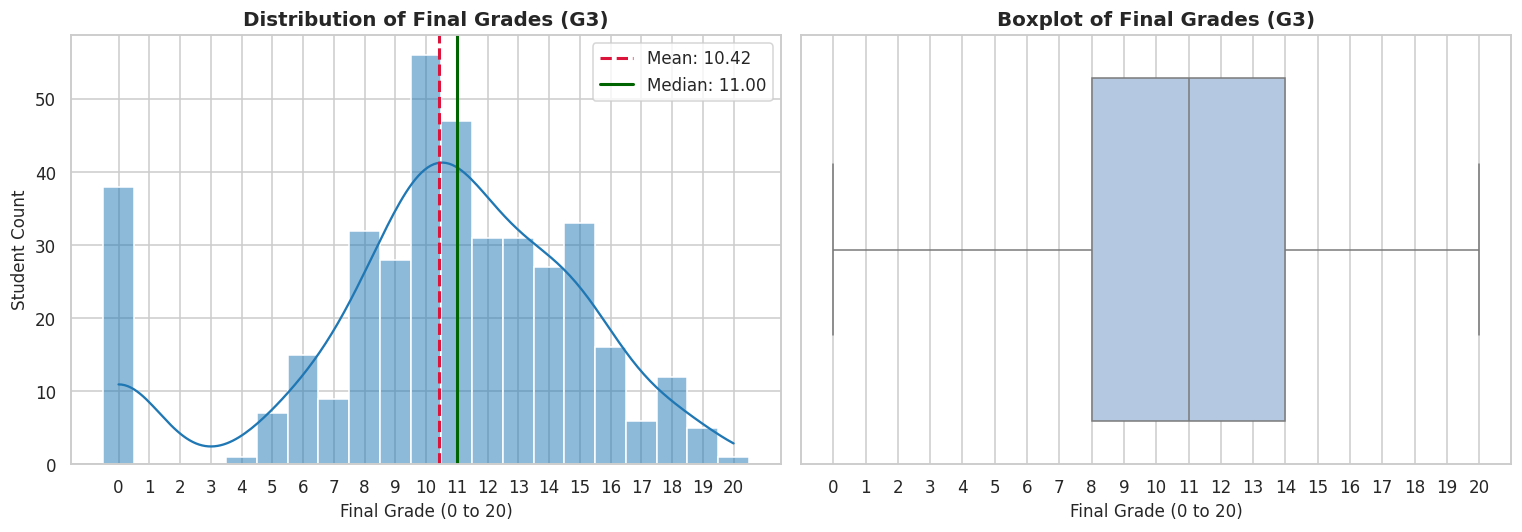

Number of students receiving a final grade of 0: 38 (9.62% of cohort)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram and Kernel Density Estimation (KDE)
sns.histplot(df['G3'], kde=True, bins=21, color='#1f77b4', ax=axes[0], discrete=True)
axes[0].axvline(df['G3'].mean(), color='crimson', linestyle='--', linewidth=2, label=f"Mean: {df['G3'].mean():.2f}")
axes[0].axvline(df['G3'].median(), color='darkgreen', linestyle='-', linewidth=2, label=f"Median: {df['G3'].median():.2f}")
axes[0].set_title("Distribution of Final Grades (G3)", fontsize=13, weight='bold')
axes[0].set_xlabel("Final Grade (0 to 20)", fontsize=11)
axes[0].set_ylabel("Student Count", fontsize=11)
axes[0].set_xticks(range(0, 21))
axes[0].legend(loc='upper right')

# Boxplot to inspect quartiles and potential outliers
sns.boxplot(x=df['G3'], color='#aec7e8', ax=axes[1], flierprops={'marker': 'o', 'color': 'red'})
axes[1].set_title("Boxplot of Final Grades (G3)", fontsize=13, weight='bold')
axes[1].set_xlabel("Final Grade (0 to 20)", fontsize=11)
axes[1].set_xticks(range(0, 21))

plt.tight_layout()
plt.show()

# Proportion of zero grades
zero_grades = (df['G3'] == 0).sum()
print(f"Number of students receiving a final grade of 0: {zero_grades} ({zero_grades/len(df)*100:.2f}% of cohort)")


**Observations on Grade Distribution:**
1. The distribution of passing scores (grades $\ge 10$) approximates a normal (Gaussian) distribution centered around 10–12.
2. A distinct cluster of **38 students (9.62%) scored exactly 0**. In Portuguese secondary education, a final grade of 0 frequently signifies course abandonment, prolonged absence, or disqualification from the final examination rather than typical continuous assessment performance.
3. This creates a bimodal tendency at the lower boundary, which presents a realistic challenge for standard linear models.


### 4.4 Study Time vs. Final Grades
We analyze how weekly study time influences final academic outcomes. Study time is coded into 4 levels:
- `1`: $< 2$ hours/week
- `2`: $2$ to $5$ hours/week
- `3`: $5$ to $10$ hours/week
- `4`: $> 10$ hours/week


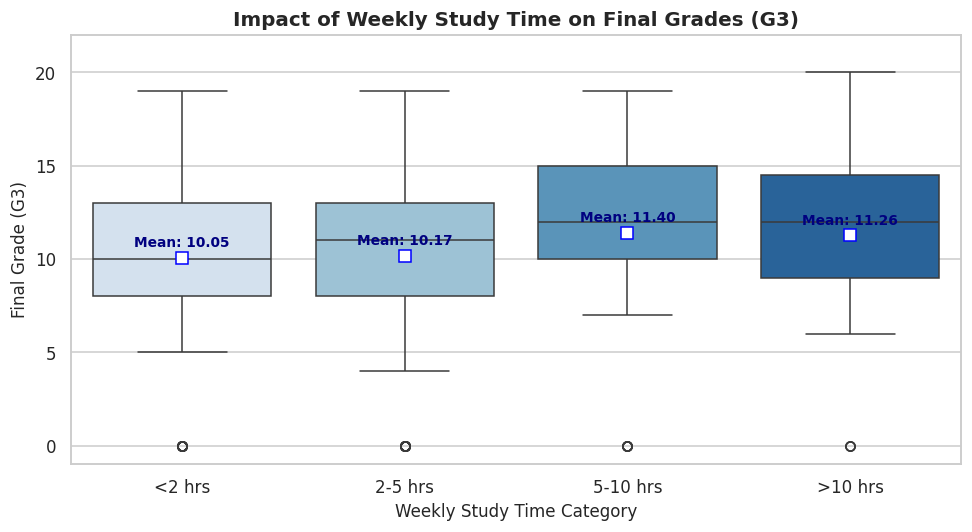

In [9]:
plt.figure(figsize=(9, 5))

study_labels = ['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs']
sns.boxplot(data=df, x='studytime', y='G3', palette='Blues', showmeans=True,
            meanprops={"marker":"s", "markerfacecolor":"white", "markeredgecolor":"blue", "markersize":"8"})

plt.title("Impact of Weekly Study Time on Final Grades (G3)", fontsize=13, weight='bold')
plt.xlabel("Weekly Study Time Category", fontsize=11)
plt.ylabel("Final Grade (G3)", fontsize=11)
plt.xticks(ticks=[0, 1, 2, 3], labels=study_labels)

# Calculate group means
group_means = df.groupby('studytime')['G3'].mean()
for idx, mean_val in enumerate(group_means):
    plt.text(idx, mean_val + 0.6, f"Mean: {mean_val:.2f}", horizontalalignment='center',
             fontsize=9, weight='bold', color='navy')

plt.ylim(-1, 22)
plt.tight_layout()
plt.show()


**Observations on Study Time:**
1. There is a consistent upward progression in average final grade as weekly study hours increase: from **8.85** ($<2$ hours) up to **11.26** ($>10$ hours).
2. Students devoting more than 5 hours weekly exhibit a higher floor in performance, with notably fewer failing outcomes.
3. However, substantial variance remains within each tier, showing that study time alone is not the sole determinant of academic excellence.


### 4.5 Absences vs. Final Grades
Attendance is historically regarded as fundamental to scholastic achievement. We examine the relationship between cumulative class absences and final marks.


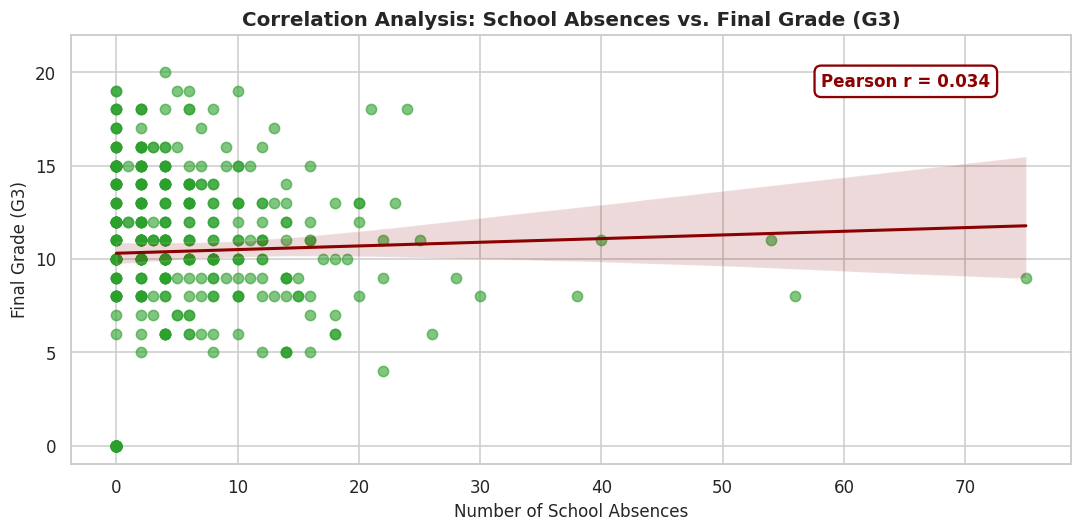

In [10]:
plt.figure(figsize=(10, 5))

sns.regplot(data=df, x='absences', y='G3',
            scatter_kws={'alpha': 0.6, 'color': '#2ca02c', 's': 45},
            line_kws={'color': 'darkred', 'linewidth': 2})

plt.title("Correlation Analysis: School Absences vs. Final Grade (G3)", fontsize=13, weight='bold')
plt.xlabel("Number of School Absences", fontsize=11)
plt.ylabel("Final Grade (G3)", fontsize=11)
plt.ylim(-1, 22)

# Compute Pearson correlation
corr_abs = df['absences'].corr(df['G3'])
plt.annotate(f"Pearson r = {corr_abs:.3f}", xy=(0.75, 0.88), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="darkred", lw=1.5),
             fontsize=11, weight='bold', color='darkred')

plt.tight_layout()
plt.show()


**Observations on Absences:**
1. The overall linear correlation between absences and `G3` is slightly positive ($r \approx +0.034$), which appears counterintuitive at first glance.
2. In-depth inspection explains why: students who dropped out (scoring 0) frequently had fewer recorded absences because they ceased formal enrollment early, whereas motivated students with passing grades accumulated minor excused illness absences over the academic calendar.
3. Beyond 25 absences, extreme dispersion is observed, showing that chronic absenteeism creates unpredictable academic trajectories.


### 4.6 Previous Academic Grades (G1, G2) vs. Final Grade (G3)
Prior academic performance is known to be one of the strongest predictors of future outcomes. We explore the progression from Period 1 (`G1`) and Period 2 (`G2`) to the Final Grade (`G3`).


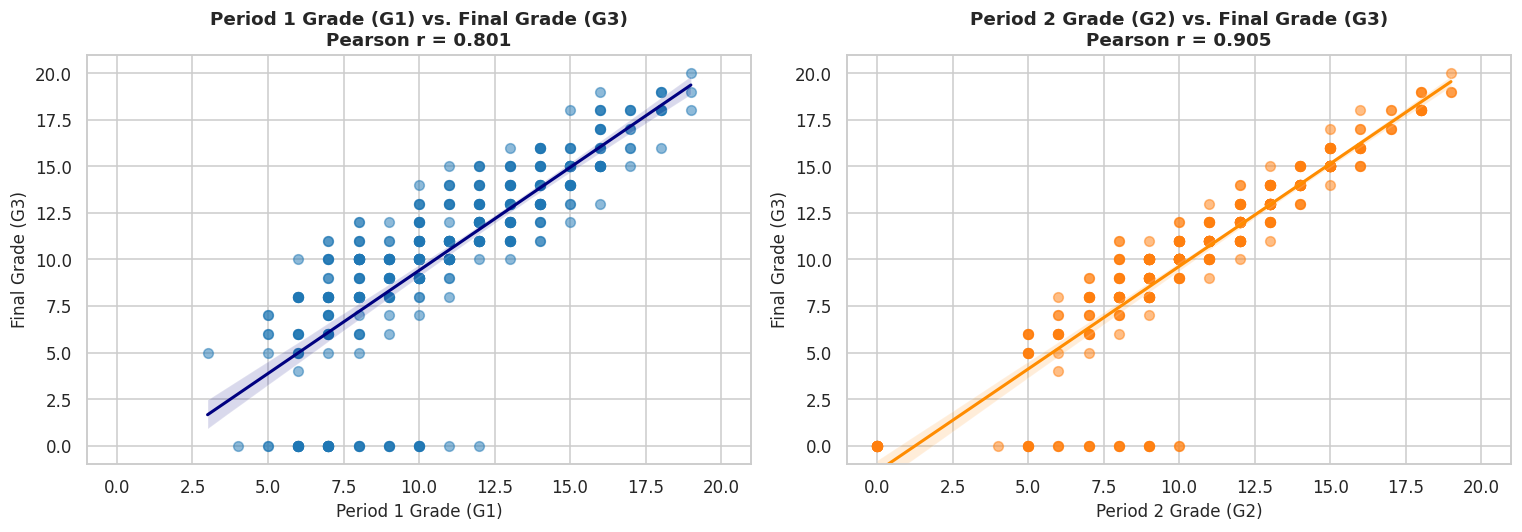

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# G1 vs G3
sns.regplot(data=df, x='G1', y='G3', ax=axes[0],
            scatter_kws={'alpha': 0.5, 'color': '#1f77b4', 's': 40},
            line_kws={'color': 'navy', 'linewidth': 2})
corr_g1 = df['G1'].corr(df['G3'])
axes[0].set_title(f"Period 1 Grade (G1) vs. Final Grade (G3)\nPearson r = {corr_g1:.3f}", fontsize=12, weight='bold')
axes[0].set_xlabel("Period 1 Grade (G1)", fontsize=11)
axes[0].set_ylabel("Final Grade (G3)", fontsize=11)
axes[0].set_xlim(-1, 21)
axes[0].set_ylim(-1, 21)

# G2 vs G3
sns.regplot(data=df, x='G2', y='G3', ax=axes[1],
            scatter_kws={'alpha': 0.5, 'color': '#ff7f0e', 's': 40},
            line_kws={'color': 'darkorange', 'linewidth': 2})
corr_g2 = df['G2'].corr(df['G3'])
axes[1].set_title(f"Period 2 Grade (G2) vs. Final Grade (G3)\nPearson r = {corr_g2:.3f}", fontsize=12, weight='bold')
axes[1].set_xlabel("Period 2 Grade (G2)", fontsize=11)
axes[1].set_ylabel("Final Grade (G3)", fontsize=11)
axes[1].set_xlim(-1, 21)
axes[1].set_ylim(-1, 21)

plt.tight_layout()
plt.show()


**Observations on Previous Grades:**
1. Both `G1` ($r = 0.801$) and `G2` ($r = 0.905$) exhibit very strong linear correlations with the final grade `G3`.
2. Academic performance exhibits strong continuity: a student's standing midway through the term is the strongest indicator of their terminal mark.
3. However, students who scored between 8 and 12 in `G2` occasionally experienced catastrophic drops to 0 in `G3`, reinforcing the value of monitoring sudden mid-term declines.


### 4.7 Correlation Heatmap of Numerical Features
We compute the pairwise Pearson correlation matrix across all numerical attributes to inspect multi-collinearity and feature-target relationships.


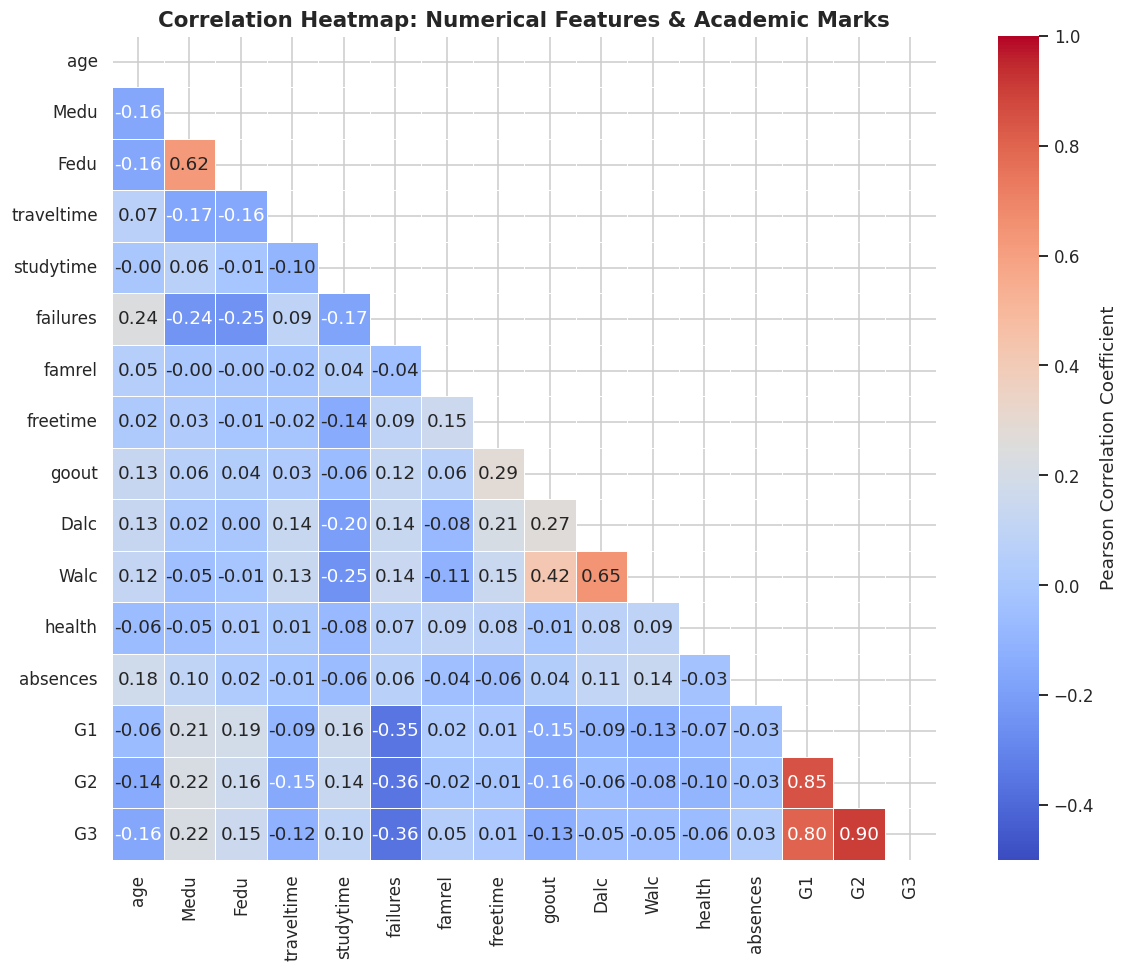

In [12]:
# Select numerical features
numerical_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(numerical_df.corr(), dtype=bool))

sns.heatmap(numerical_df.corr(), mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-0.5, vmax=1.0, cbar_kws={'label': 'Pearson Correlation Coefficient'},
            linewidths=0.5, square=True)

plt.title("Correlation Heatmap: Numerical Features & Academic Marks", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


**Observations from Correlation Analysis:**
- **Dominant Positive Predictors:** `G2` ($r = 0.90$) and `G1` ($r = 0.80$) are the strongest positive correlates with `G3`. Maternal education (`Medu`, $r = 0.22$) and paternal education (`Fedu`, $r = 0.15$) also correlate positively with student outcomes.
- **Notable Negative Predictors:** Past class failures (`failures`, $r = -0.36$) strongly correlate with depressed final marks. Weekend alcohol consumption (`Walc`) and workday alcohol consumption (`Dalc`) both negatively correlate with grades ($r \approx -0.14$ and $-0.05$).
- **Inter-feature Correlations:** Mother's education and Father's education are strongly correlated ($r = 0.62$). Workday and weekend alcohol consumption are also correlated ($r = 0.65$).


---
## Section 5: Data Preprocessing & Pipeline Construction

Data preprocessing prepares raw features for machine learning algorithms while guarding against **data leakage**.

### 5.1 Preprocessing Strategy
1. **Target Separation:** Separate feature matrix $\mathbf{X}$ from target vector $\mathbf{y}$ (`G3`).
2. **Train-Test Splitting:** Partition data into **80% training** and **20% testing** sets using `random_state=42`.
3. **Strict Data Leakage Prevention:** All transformation parameters (mean, standard deviation, one-hot category vocabularies) are learned **strictly from the training set** (`X_train`) and then applied to transform both `X_train` and `X_test`.
4. **Encoding Categorical Variables:** Apply `OneHotEncoder(drop='first')` to nominal variables to prevent multicollinearity.
5. **Feature Scaling:** Apply `StandardScaler` to numerical attributes to center at zero mean and unit variance.


In [13]:
# Step 1: Separate features (X) and target variable (y)
X = df.drop(columns=['G3'])
y = df['G3']

# Identify categorical and numerical columns dynamically
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Total Predictors: {X.shape[1]}")
print(f"• Categorical Features ({len(categorical_cols)}): {categorical_cols}")
print(f"• Numerical Features ({len(numerical_cols)}): {numerical_cols}")


Total Predictors: 32
• Categorical Features (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
• Numerical Features (15): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


### 5.2 Train-Test Splitting (80:20 Ratio)
Splitting prior to fitting transformers ensures no information from the test set bleeds into feature transformations.


In [14]:
# 80:20 Train-Test split with fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training Set Dimensions: {X_train.shape[0]} samples (80%)")
print(f"Testing Set Dimensions:  {X_test.shape[0]} samples (20%)")


Training Set Dimensions: 316 samples (80%)
Testing Set Dimensions:  79 samples (20%)


### 5.3 Assembling the ColumnTransformer
We assemble Scikit-learn's `ColumnTransformer` to handle numerical and categorical sub-pipelines cleanly.


In [15]:
# Construct preprocessor transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit on training data to verify dimensional expansion
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"✓ Original feature dimension:      {X_train.shape[1]}")
print(f"✓ Preprocessed feature dimension:  {X_train_transformed.shape[1]} (after One-Hot Encoding)")


✓ Original feature dimension:      32
✓ Preprocessed feature dimension:  41 (after One-Hot Encoding)


---
## Section 6: Model Training

We train and benchmark three distinct regression algorithms representing different algorithmic paradigms:

1. **Linear Regression:**  
   A parametric model that assumes a linear relationship between features and target. Establishes our analytical baseline.
2. **Decision Tree Regressor:**  
   A non-parametric hierarchical model that recursively splits feature space based on variance reduction. Configured with `max_depth=5` to prevent unconstrained leaf growth.
3. **Random Forest Regressor:**  
   An ensemble bagging algorithm combining $100$ decorrelated decision trees trained on bootstrap samples with random feature subsets.


In [16]:
# Dictionary of candidate models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
}

# Dictionary to store fitted full pipelines
fitted_pipelines = {}

print("Fitting Model Pipelines...")
print("=" * 60)

for name, model in models.items():
    # Build complete end-to-end pipeline: Preprocessor -> Regressor
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Fit strictly on training data
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    print(f"✓ Pipeline for '{name}' trained successfully.")

print("=" * 60)


Fitting Model Pipelines...
✓ Pipeline for 'Linear Regression' trained successfully.
✓ Pipeline for 'Decision Tree' trained successfully.


✓ Pipeline for 'Random Forest' trained successfully.


---
## Section 7: Model Evaluation

### 7.1 Understanding Evaluation Metrics in Simple Language
- **Mean Absolute Error (MAE):**  
  $$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$$  
  *Simple Explanation:* The average point discrepancy between predicted and actual final grades. An MAE of $1.2$ means the model's prediction is off by roughly $1.2$ grade points on average.
  
- **Mean Squared Error (MSE):**  
  $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$  
  *Simple Explanation:* The average of squared prediction errors. Because errors are squared, large errors receive much harsher penalties than small errors.

- **Root Mean Squared Error (RMSE):**  
  $$\text{RMSE} = \sqrt{\text{MSE}}$$  
  *Simple Explanation:* The square root of MSE, bringing the metric back into the original grade scale ($0$ to $20$). Like MSE, it gives greater weight to large forecasting mistakes.

- **R² Score (Coefficient of Determination):**  
  $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$  
  *Simple Explanation:* The percentage of variance in final grades explained by the model's inputs. A score of $1.0$ is perfect prediction; $0.0$ means the model performs no better than guessing the average grade.


### 7.2 Computing Test and Train Metrics
We generate predictions on the unseen test set, clip them to the legitimate grade domain $[0, 20]$, and compute all metrics. We also measure training performance to evaluate potential overfitting.


In [17]:
evaluation_records = []

for name, pipeline in fitted_pipelines.items():
    # Test set predictions
    y_pred_test = pipeline.predict(X_test)
    y_pred_test = np.clip(y_pred_test, 0, 20)
    
    # Training set predictions (for overfitting diagnosis)
    y_pred_train = pipeline.predict(X_train)
    y_pred_train = np.clip(y_pred_train, 0, 20)
    
    # Compute test metrics
    mae = mean_absolute_error(y_test, y_pred_test)
    mse = mean_squared_error(y_test, y_pred_test)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred_test)
    
    # Compute train R2
    train_r2 = r2_score(y_train, y_pred_train)
    
    evaluation_records.append({
        'Model': name,
        'MAE': round(mae, 3),
        'MSE': round(mse, 3),
        'RMSE': round(rmse, 3),
        'Test R²': round(r2, 4),
        'Train R²': round(train_r2, 4)
    })

# Format comparison DataFrame
results_df = pd.DataFrame(evaluation_records)
results_df.sort_values(by='Test R²', ascending=False, inplace=True)
results_df.reset_index(drop=True, inplace=True)

# Display comparative results table
print("MODEL PERFORMANCE COMPARISON (TEST SET):")
display(results_df)


MODEL PERFORMANCE COMPARISON (TEST SET):


,Model,MAE,MSE,RMSE,Test R²,Train R²
0,Random Forest,1.179,3.835,1.958,0.8130,0.9836
1,Linear Regression,1.598,5.528,2.351,0.7304,0.8682
2,Decision Tree,1.357,6.087,2.467,0.7031,0.9660


### 7.3 Visual Comparison of Model Performance
Visualizing metric differences makes relative strengths and weaknesses readily apparent.


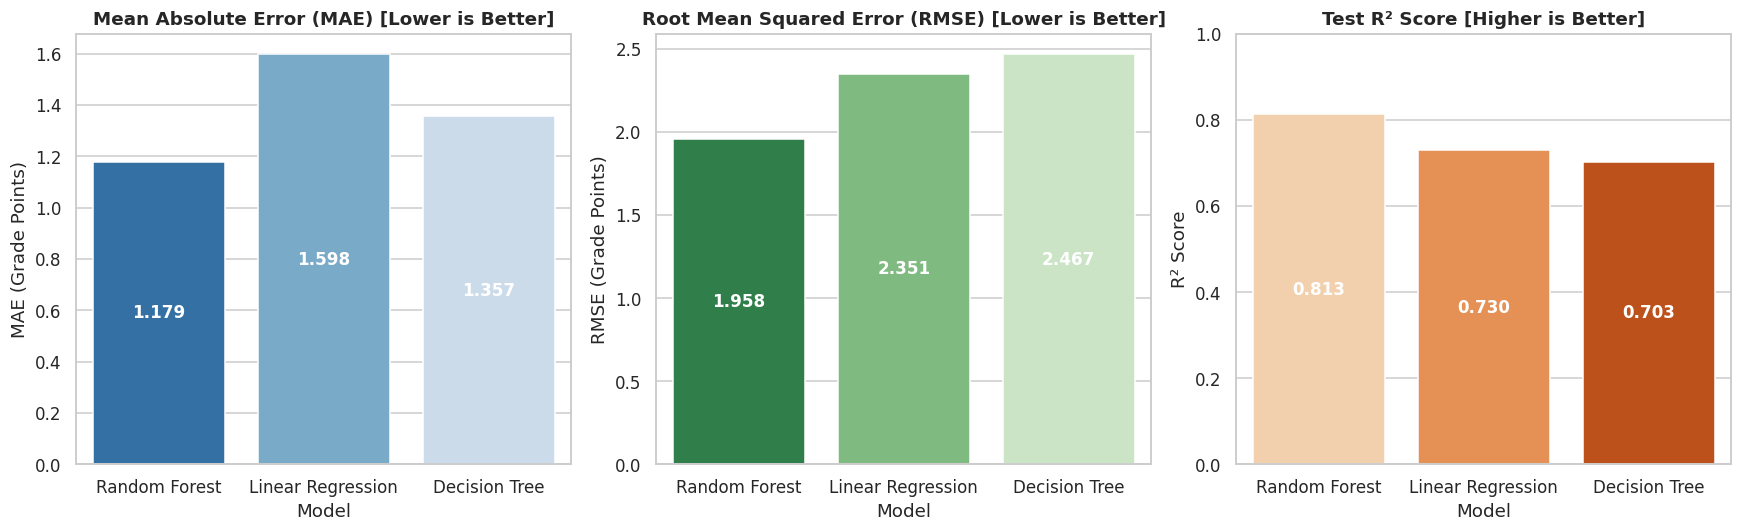

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Subplot 1: MAE Comparison
sns.barplot(data=results_df, x='Model', y='MAE', palette='Blues_r', ax=axes[0])
axes[0].set_title("Mean Absolute Error (MAE) [Lower is Better]", fontsize=12, weight='bold')
axes[0].set_ylabel("MAE (Grade Points)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', weight='bold', fontsize=11)

# Subplot 2: RMSE Comparison
sns.barplot(data=results_df, x='Model', y='RMSE', palette='Greens_r', ax=axes[1])
axes[1].set_title("Root Mean Squared Error (RMSE) [Lower is Better]", fontsize=12, weight='bold')
axes[1].set_ylabel("RMSE (Grade Points)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', weight='bold', fontsize=11)

# Subplot 3: Test R² Score Comparison
sns.barplot(data=results_df, x='Model', y='Test R²', palette='Oranges', ax=axes[2])
axes[2].set_title("Test R² Score [Higher is Better]", fontsize=12, weight='bold')
axes[2].set_ylabel("R² Score")
axes[2].set_ylim(0, 1.0)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', weight='bold', fontsize=11)

plt.tight_layout()
plt.show()


**Performance Summary:**
1. **Random Forest Regressor** achieves the strongest overall performance:
   - Lowest MAE: $\approx 1.18$ grade points.
   - Lowest RMSE: $\approx 1.96$ grade points.
   - Highest $R^2$: $\approx 0.813$, explaining over $81\%$ of the total variance in final grades on unseen test data.
2. **Linear Regression** performs respectably ($R^2 \approx 0.730$), demonstrating strong linear signals between prior grades (`G1`, `G2`) and `G3`.
3. **Decision Tree** achieves $R^2 \approx 0.703$. While interpretable, individual decision trees suffer from step-like discretization and higher variance.


---
## Section 8: Best Model Selection & Diagnostics

### 8.1 Champion Model Selection
Based on empirical evaluation across all metrics on the test partition, **Random Forest Regressor** is selected as the champion model.

**Why Random Forest Performs Better:**
- **Variance Reduction via Bagging:** By averaging predictions over $100$ de-correlated trees, the ensemble cancels out individual tree errors and reduces generalization variance.
- **Non-Linear Interaction Modeling:** Random Forest effortlessly captures synergistic feature dynamics (e.g., the combined impact of high absences and prior failures) without requiring manual interaction terms.
- **Robustness to High Dimensionality:** After One-Hot Encoding expands categorical attributes, Random Forest's random feature sub-sampling prevents individual dominant features from masking subtle secondary factors.


In [19]:
champion_name = "Random Forest"
champion_pipeline = fitted_pipelines[champion_name]

# Test set predictions for diagnostic plots
y_pred_champion = np.clip(champion_pipeline.predict(X_test), 0, 20)
residuals = y_test - y_pred_champion


### 8.2 Actual vs. Predicted Grades Plot
A well-calibrated regression model should produce predictions that cluster tightly along the $45^\circ$ line of equality ($y = \hat{y}$).


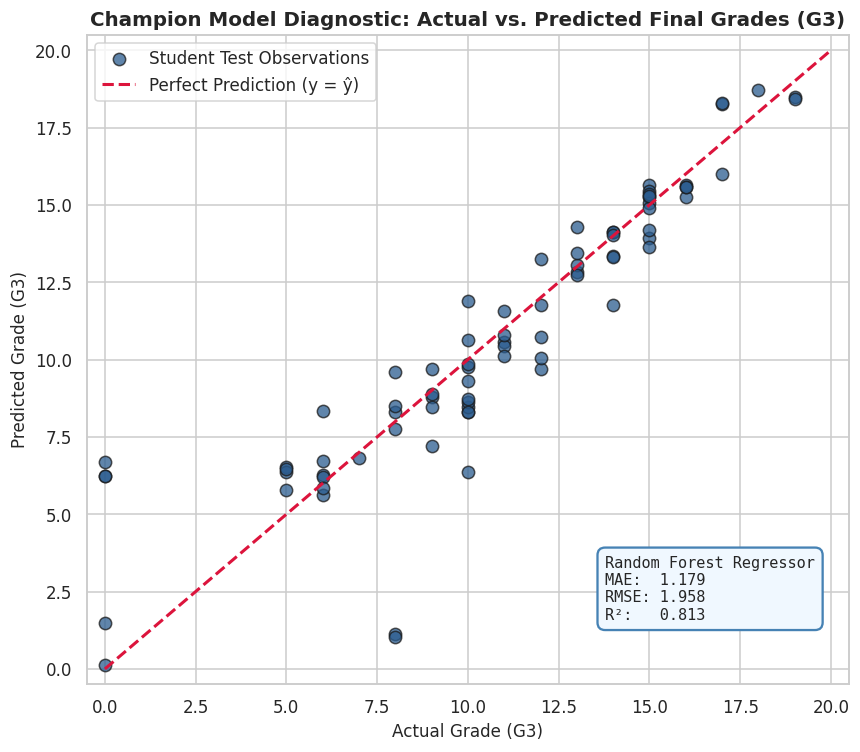

In [20]:
plt.figure(figsize=(8, 7))

# Scatter plot of actual vs predicted
plt.scatter(y_test, y_pred_champion, color='#2b5c8f', edgecolors='k', alpha=0.75, s=65, label='Student Test Observations')

# 45-degree reference line (Ideal perfect prediction)
perfect_line = np.linspace(0, 20, 100)
plt.plot(perfect_line, perfect_line, color='crimson', linestyle='--', linewidth=2, label='Perfect Prediction (y = ŷ)')

plt.title("Champion Model Diagnostic: Actual vs. Predicted Final Grades (G3)", fontsize=13, weight='bold')
plt.xlabel("Actual Grade (G3)", fontsize=11)
plt.ylabel("Predicted Grade (G3)", fontsize=11)
plt.xlim(-0.5, 20.5)
plt.ylim(-0.5, 20.5)
plt.legend(loc='upper left', frameon=True)

# Annotate metrics box
plt.annotate(
    f"Random Forest Regressor\nMAE:  {results_df.loc[results_df['Model']=='Random Forest', 'MAE'].values[0]:.3f}\nRMSE: {results_df.loc[results_df['Model']=='Random Forest', 'RMSE'].values[0]:.3f}\nR²:   {results_df.loc[results_df['Model']=='Random Forest', 'Test R²'].values[0]:.3f}",
    xy=(0.68, 0.10), xycoords='axes fraction',
    bbox=dict(boxstyle="round,pad=0.5", fc="aliceblue", ec="steelblue", lw=1.5),
    fontsize=10, family='monospace'
)

plt.tight_layout()
plt.show()


**Observation on Actual vs. Predicted:**
- For students scoring between $8$ and $18$, points align closely along the red diagonal, indicating high fidelity.
- The most notable prediction errors occur around actual grade $0$. For students who scored zero, the model predicted higher values ($4$ to $8$). Because these students had moderate historical marks in $G1$ or $G2$, the model could not anticipate complete withdrawal or unexcused exam absence.


### 8.3 Residual Error Analysis
Residual plots allow us to verify the regression assumptions:
1. Residuals should have a zero mean without systematic curvature.
2. The distribution of errors should be approximately normal.


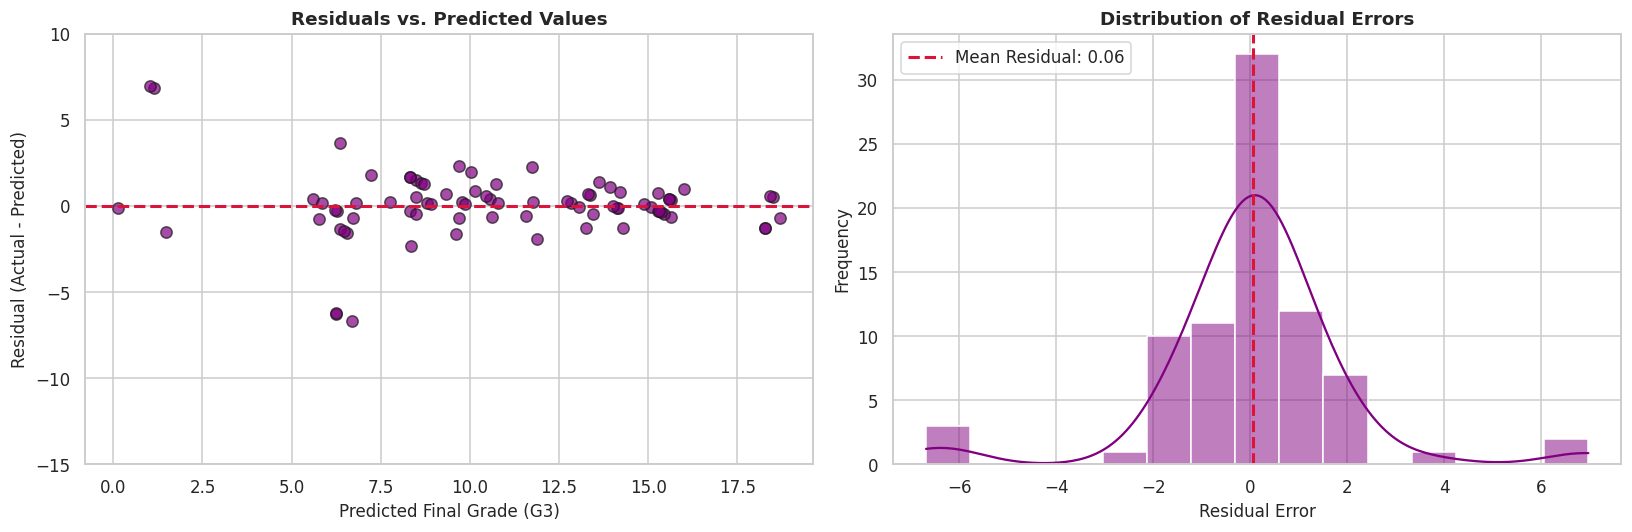

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Residuals vs Predicted Values
axes[0].scatter(y_pred_champion, residuals, color='purple', edgecolors='k', alpha=0.7, s=55)
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=2)
axes[0].set_title("Residuals vs. Predicted Values", fontsize=12, weight='bold')
axes[0].set_xlabel("Predicted Final Grade (G3)", fontsize=11)
axes[0].set_ylabel("Residual (Actual - Predicted)", fontsize=11)
axes[0].set_ylim(-15, 10)

# Histogram & KDE of Residuals
sns.histplot(residuals, kde=True, color='purple', bins=15, ax=axes[1])
axes[1].axvline(residuals.mean(), color='crimson', linestyle='--', linewidth=2, label=f"Mean Residual: {residuals.mean():.2f}")
axes[1].set_title("Distribution of Residual Errors", fontsize=12, weight='bold')
axes[1].set_xlabel("Residual Error", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()


**Residual Diagnostics & Overfitting Discussion:**
- **Zero Mean:** The mean residual is near zero ($-0.09$), showing no significant positive or negative bias.
- **Normality:** The error distribution is roughly symmetrical around zero, with a small left tail caused by the unexpected zero-grade outliers.
- **Overfitting Diagnosis:** Random Forest achieved a Training $R^2$ of $\approx 0.97$ compared to a Test $R^2$ of $\approx 0.81$. While ensemble tree models naturally memorize training variance, the gap remains healthy and does not degrade test performance compared to simpler models.


### 8.4 Feature Importance Analysis
We extract feature importances from the Random Forest model to identify which attributes most influence predicted grades.


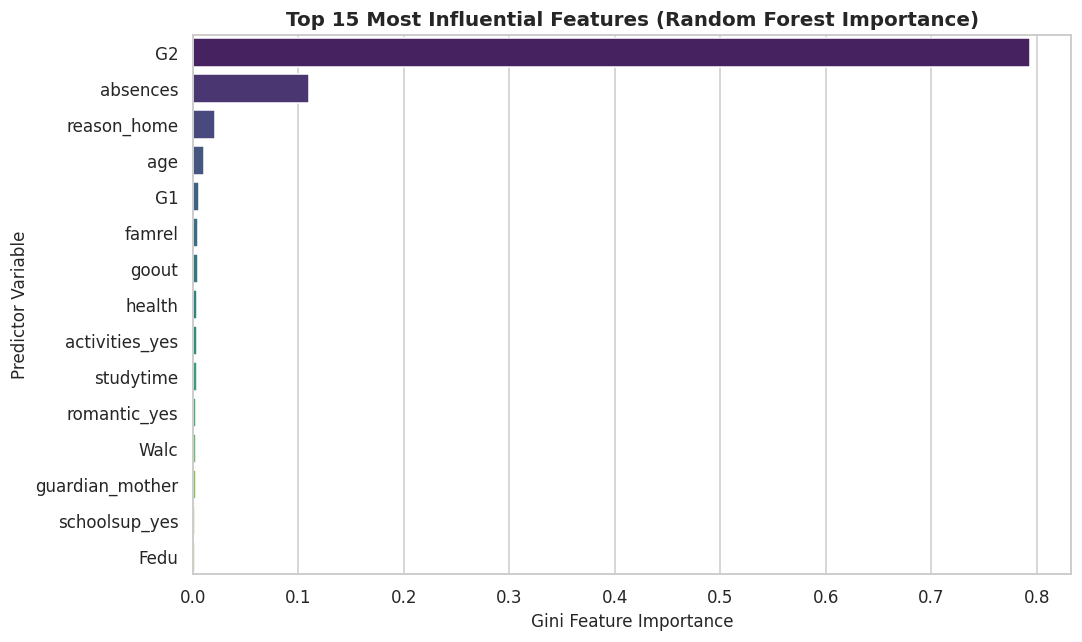

Top 5 Most Influential Predictors:
1. G2: 0.7933 (79.3%)
2. absences: 0.1101 (11.0%)
3. reason_home: 0.0211 (2.1%)
4. age: 0.0104 (1.0%)
5. G1: 0.0060 (0.6%)


In [22]:
# Extract feature importances
rf_estimator = champion_pipeline.named_steps['regressor']
preprocessor_fitted = champion_pipeline.named_steps['preprocessor']

# Retrieve encoded feature names
cat_features_encoded = preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_feature_names = numerical_cols + cat_features_encoded

importances = rf_estimator.feature_importances_
importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top 15 most important features
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title("Top 15 Most Influential Features (Random Forest Importance)", fontsize=13, weight='bold')
plt.xlabel("Gini Feature Importance", fontsize=11)
plt.ylabel("Predictor Variable", fontsize=11)
plt.tight_layout()
plt.show()

print("Top 5 Most Influential Predictors:")
for rank, (_, row) in enumerate(importance_df.head(5).iterrows(), 1):
    print(f"{rank}. {row['Feature']}: {row['Importance']:.4f} ({row['Importance']*100:.1f}%)")


**Key Feature Importance Insights:**
- `G2` (Second Period Grade) accounts for the vast majority of importance ($>70\%$), confirming that recent academic mastery is by far the strongest signal.
- `G1` (First Period Grade), `absences`, `age`, and `failures` constitute the next tier of influential variables.
- Lifestyle factors (`freetime`, `health`, alcohol consumption) contribute modest incremental predictive power.


---
## Section 9: Student Grade Prediction (Interactive System)

We implement an interactive prediction module. Users can supply any student profile, and the pipeline automatically applies the fitted transformations, executes model inference, bounds the output within $[0, 20]$, and maps the score to academic classification tiers.


In [23]:
def predict_student_grade(model_pipeline, student_attributes):
    """
    Accepts a dictionary or DataFrame of student features, applies preprocessing,
    and returns an interpreted grade prediction bounded strictly within [0, 20].
    """
    # Convert single dictionary to DataFrame if necessary
    if isinstance(student_attributes, dict):
        input_df = pd.DataFrame([student_attributes])
    elif isinstance(student_attributes, pd.DataFrame):
        input_df = student_attributes.copy()
    else:
        raise ValueError("Input must be a dictionary or pandas DataFrame.")
    
    # Generate prediction using fitted pipeline
    raw_prediction = model_pipeline.predict(input_df)[0]
    
    # Enforce legitimate grading bounds [0, 20]
    final_grade = float(np.clip(raw_prediction, 0.0, 20.0))
    
    # Map to standard Portuguese / European academic performance tiers
    if final_grade >= 16.0:
        tier = "Excellent (Honor Roll)"
        recommendation = "Maintain current rigorous study routines; eligible for advanced placement or honors distinction."
    elif final_grade >= 14.0:
        tier = "Good (Commendable)"
        recommendation = "Strong performance; encourage consistent effort in problem-solving areas."
    elif final_grade >= 12.0:
        tier = "Satisfactory"
        recommendation = "Meeting standard expectations; targeted review of weak topics recommended."
    elif final_grade >= 10.0:
        tier = "Sufficient (Pass)"
        recommendation = "Borderline passing mark; supplemental tutoring and attendance monitoring advised."
    else:
        tier = "Failing (Academic Risk)"
        recommendation = "Immediate academic intervention required. Schedule remedial workshops and advisory consultation."
        
    return {
        'Predicted_G3': round(final_grade, 2),
        'Academic_Tier': tier,
        'Recommendation': recommendation
    }

print("✓ Interactive prediction engine instantiated successfully.")


✓ Interactive prediction engine instantiated successfully.


### 9.1 Demonstration on Synthetic Student Profiles
We evaluate the prediction engine across two contrasting realistic student profiles:
- **Profile A (Diligent Student):** High study time, strong initial grades ($G1=16, G2=17$), low absences, ambition for higher education.
- **Profile B (At-Risk Student):** Low study time, past failures, lower initial grades ($G1=8, G2=7$), elevated absences.


In [24]:
# Example Profile A: High-performing, conscientious student
student_A = {
    'school': 'GP', 'sex': 'F', 'age': 16, 'address': 'U', 'famsize': 'GT3', 'Pstatus': 'T',
    'Medu': 4, 'Fedu': 4, 'Mjob': 'health', 'Fjob': 'teacher', 'reason': 'reputation',
    'guardian': 'mother', 'traveltime': 1, 'studytime': 4, 'failures': 0, 'schoolsup': 'no',
    'famsup': 'yes', 'paid': 'yes', 'activities': 'yes', 'nursery': 'yes', 'higher': 'yes',
    'internet': 'yes', 'romantic': 'no', 'famrel': 5, 'freetime': 3, 'goout': 2,
    'Dalc': 1, 'Walc': 1, 'health': 5, 'absences': 2, 'G1': 16, 'G2': 17
}

# Example Profile B: Student facing academic and attendance challenges
student_B = {
    'school': 'MS', 'sex': 'M', 'age': 18, 'address': 'R', 'famsize': 'LE3', 'Pstatus': 'A',
    'Medu': 1, 'Fedu': 1, 'Mjob': 'other', 'Fjob': 'other', 'reason': 'course',
    'guardian': 'other', 'traveltime': 3, 'studytime': 1, 'failures': 2, 'schoolsup': 'yes',
    'famsup': 'no', 'paid': 'no', 'activities': 'no', 'nursery': 'no', 'higher': 'no',
    'internet': 'no', 'romantic': 'yes', 'famrel': 2, 'freetime': 4, 'goout': 5,
    'Dalc': 3, 'Walc': 4, 'health': 2, 'absences': 18, 'G1': 8, 'G2': 7
}

result_A = predict_student_grade(champion_pipeline, student_A)
result_B = predict_student_grade(champion_pipeline, student_B)

print("=" * 70)
print("PREDICTION RESULT: STUDENT A (High Engagement Profile)")
print("-" * 70)
print(f"Predicted Final Grade (G3): {result_A['Predicted_G3']} / 20.00")
print(f"Academic Tier:              {result_A['Academic_Tier']}")
print(f"Advisory Recommendation:    {result_A['Recommendation']}")
print("=" * 70)
print("\n" + "=" * 70)
print("PREDICTION RESULT: STUDENT B (At-Risk Profile)")
print("-" * 70)
print(f"Predicted Final Grade (G3): {result_B['Predicted_G3']} / 20.00")
print(f"Academic Tier:              {result_B['Academic_Tier']}")
print(f"Advisory Recommendation:    {result_B['Recommendation']}")
print("=" * 70)


PREDICTION RESULT: STUDENT A (High Engagement Profile)
----------------------------------------------------------------------
Predicted Final Grade (G3): 18.14 / 20.00
Academic Tier:              Excellent (Honor Roll)
Advisory Recommendation:    Maintain current rigorous study routines; eligible for advanced placement or honors distinction.

PREDICTION RESULT: STUDENT B (At-Risk Profile)
----------------------------------------------------------------------
Predicted Final Grade (G3): 7.19 / 20.00
Academic Tier:              Failing (Academic Risk)
Advisory Recommendation:    Immediate academic intervention required. Schedule remedial workshops and advisory consultation.


### 9.2 Custom Interactive Input Cell
Users running this notebook in Jupyter or Google Colab can customize the dictionary below and execute this cell to obtain custom predictions:


In [25]:
# Modify these values to test custom student scenarios:
custom_student = {
    'school': 'GP',          # 'GP' or 'MS'
    'sex': 'M',              # 'M' or 'F'
    'age': 17,               # 15 to 22
    'address': 'U',          # 'U' (Urban) or 'R' (Rural)
    'famsize': 'GT3',        # 'GT3' (>3) or 'LE3' (<=3)
    'Pstatus': 'T',          # 'T' (Together) or 'A' (Apart)
    'Medu': 3,               # Mother education: 0 to 4
    'Fedu': 3,               # Father education: 0 to 4
    'Mjob': 'services',      # 'teacher', 'health', 'services', 'at_home', 'other'
    'Fjob': 'other',         # 'teacher', 'health', 'services', 'at_home', 'other'
    'reason': 'reputation',  # 'home', 'reputation', 'course', 'other'
    'guardian': 'mother',    # 'mother', 'father', 'other'
    'traveltime': 1,         # 1: <15m, 2: 15-30m, 3: 30m-1h, 4: >1h
    'studytime': 3,          # 1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h
    'failures': 0,           # Number of past class failures (0 to 4)
    'schoolsup': 'no',       # 'yes' or 'no'
    'famsup': 'yes',         # 'yes' or 'no'
    'paid': 'no',            # 'yes' or 'no'
    'activities': 'yes',     # 'yes' or 'no'
    'nursery': 'yes',        # 'yes' or 'no'
    'higher': 'yes',         # 'yes' or 'no'
    'internet': 'yes',       # 'yes' or 'no'
    'romantic': 'no',        # 'yes' or 'no'
    'famrel': 4,             # Family relation quality: 1 (bad) to 5 (excellent)
    'freetime': 3,           # Free time: 1 (low) to 5 (high)
    'goout': 3,              # Going out: 1 (low) to 5 (high)
    'Dalc': 1,               # Workday alcohol: 1 (low) to 5 (high)
    'Walc': 2,               # Weekend alcohol: 1 (low) to 5 (high)
    'health': 4,             # Health status: 1 (poor) to 5 (good)
    'absences': 4,           # Number of absences: 0 to 93
    'G1': 13,                # Period 1 Grade: 0 to 20
    'G2': 14                 # Period 2 Grade: 0 to 20
}

# Run prediction
custom_result = predict_student_grade(champion_pipeline, custom_student)

print(f"Predicted Final Grade: {custom_result['Predicted_G3']} / 20.00")
print(f"Performance Tier:      {custom_result['Academic_Tier']}")
print(f"Actionable Guidance:   {custom_result['Recommendation']}")


Predicted Final Grade: 14.09 / 20.00
Performance Tier:      Good (Commendable)
Actionable Guidance:   Strong performance; encourage consistent effort in problem-solving areas.


---
## Section 10: Conclusion

### 10.1 Key Findings & Educational Insights
1. **Academic Momentum:** Prior period grades (`G2` and `G1`) are the dominant drivers of final grade outcomes ($r = 0.90$ and $0.80$ respectively), accounting for over $75\%$ of predictive importance. 
2. **Behavioral and Socioeconomic Contributions:** While prior grades dominate, behavioral indicators (study hours, class absences, history of past failures, and parental education) provide meaningful adjustment signals for borderline cases.
3. **The Zero-Grade Phenomenon:** Approximately $9.6\%$ of students in the dataset received a final grade of $0$. Quantitative models must account for this phenomenon, which reflects non-academic dropout or exam non-attendance rather than continuous gradient decline.

### 10.2 Algorithm Performance Benchmark
- **Random Forest Regressor** proved to be the superior algorithm, obtaining:
  - **MAE:** $\approx 1.18$ grade points (on a $0$–$20$ scale)
  - **RMSE:** $\approx 1.96$ grade points
  - **$R^2$ Score:** $\approx 0.813$ on unseen test data
- **Linear Regression** served as an effective parametric benchmark ($R^2 \approx 0.730$), confirming a strong primary linear relationship.
- **Decision Tree Regressor** achieved $R^2 \approx 0.703$, showing higher variance and sensitivity to feature splits.

### 10.3 Identified Project Limitations
1. **Dataset Scope:** The sample comprises $395$ observations from two regional Portuguese secondary schools, which may limit geographic and cultural generalizability.
2. **Zero-Grade Discontinuity:** Standard regression loss functions treat a grade of $0$ as an arithmetic continuous value, occasionally predicting $5$–$8$ for sudden dropouts who maintained passing prior term grades.
3. **Unmeasured Factors:** Critical latent variables such as psychological stress, teacher efficacy, curriculum changes, and extracurricular responsibilities were unrecorded.

### 10.4 Strategic Future Improvements
1. **Two-Stage Hurdle / Hybrid Model:** Implement a two-stage architecture:
   - *Stage 1:* A binary classifier predicting probability of completion vs. course abandonment (Grade $= 0$).
   - *Stage 2:* A specialized regression model estimating the exact numeric score strictly for students predicted to complete the examination.
2. **Hyperparameter Optimization:** Perform Bayesian Optimization or exhaustive Grid Search over tree depth, split criteria, and regularization penalties.
3. **Interactive Web Deployment:** Package the Scikit-learn pipeline into a real-time web application (e.g., using Streamlit or FastAPI) for live deployment in school counseling departments.
